# Clustering movies by metadata

Clean movie metadata, encode genres, companies, countries and languages, then explore PCA and K-means clusters. Install pandas, NumPy, Matplotlib, seaborn, and scikit-learn. The metadata CSV must be downloaded separately.

Silhouette scores use a reproducible sample of up to 2,000 movies to avoid a full quadratic distance matrix. The last comparison samples up to 500 movies from each group. These are approximations, and cluster labels are descriptive rather than ground truth.

**Data:** [The Movies Dataset](https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset). Place `movies_metadata.csv` in this folder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('movies_metadata.csv', low_memory=False)

df.head()

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


In [2]:
df.shape

(45466, 24)

In [3]:
df.isna().sum()

adult                        0
belongs_to_collection    40972
budget                       0
genres                       0
homepage                 37684
id                           0
imdb_id                     17
original_language           11
original_title               0
overview                   954
popularity                   5
poster_path                386
production_companies         3
production_countries         3
release_date                87
revenue                      6
runtime                    263
spoken_languages             6
status                      87
tagline                  25054
title                        6
video                        6
vote_average                 6
vote_count                   6
dtype: int64

In [4]:
cols_to_drop = ['belongs_to_collection', 'homepage', 'tagline', 'poster_path']
df = df.drop(columns=cols_to_drop, errors='ignore')

In [5]:
df = df.dropna(subset=['production_countries', 'imdb_id', 'original_language', 'popularity', 'production_companies', 'production_countries', 'revenue', 'spoken_languages', 'title', 'video', 'vote_average', 'release_date', 'overview'])

In [6]:
df['status'] = df['status'].fillna(df['status'].mode()[0])
df['runtime'] = df['runtime'].fillna(df['runtime'].median())

In [7]:
df.isna().sum()

adult                   0
budget                  0
genres                  0
id                      0
imdb_id                 0
original_language       0
original_title          0
overview                0
popularity              0
production_companies    0
production_countries    0
release_date            0
revenue                 0
runtime                 0
spoken_languages        0
status                  0
title                   0
video                   0
vote_average            0
vote_count              0
dtype: int64

In [8]:
df.head()

,adult,budget,genres,id,imdb_id,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,title,video,vote_average,vote_count
0,False,30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",21.946943,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Toy Story,False,7.7,5415.0
1,False,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,17.015539,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Jumanji,False,6.9,2413.0
2,False,0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,11.7129,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Grumpier Old Men,False,6.5,92.0
3,False,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",3.859495,[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Waiting to Exhale,False,6.1,34.0
4,False,0,"[{'id': 35, 'name': 'Comedy'}]",11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,8.387519,"[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Father of the Bride Part II,False,5.7,173.0


In [9]:
df['year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

In [10]:
from ast import literal_eval

def parse_genres(x):
    try:
        return [d['name'] for d in literal_eval(x)]
    except:
        return []

df['genres_list'] = df['genres'].apply(parse_genres)

In [11]:
df = df.drop(columns = ['genres', 'release_date'], errors='ignore')

In [12]:
def extract_company_names(text):
    try:
        items = literal_eval(text)
        return [d['name'] for d in items if isinstance(d, dict) and 'name' in d]
    except:
        return []

def extract_country_iso(text):
    try:
        items = literal_eval(text)
        return [d['iso_3166_1'] for d in items if isinstance(d, dict) and 'iso_3166_1' in d]
    except:
        return []

def extract_language_iso(text):
    try:
        items = literal_eval(text)
        return [d['iso_639_1'] for d in items if isinstance(d, dict) and 'iso_639_1' in d]
    except:
        return []

df['companies_list']     = df['production_companies'].apply(extract_company_names)
df['countries_iso_list'] = df['production_countries'].apply(extract_country_iso)
df['spoken_iso_list']    = df['spoken_languages'].apply(extract_language_iso)

In [13]:
df = df.drop(columns = ['production_companies', 'production_countries', 'spoken_languages'], errors='ignore')

In [14]:
df.head()

,adult,budget,id,imdb_id,original_language,original_title,overview,popularity,revenue,runtime,status,title,video,vote_average,vote_count,year,genres_list,companies_list,countries_iso_list,spoken_iso_list
0,False,30000000,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",21.946943,373554033.0,81.0,Released,Toy Story,False,7.7,5415.0,1995,"[Animation, Comedy, Family]",[Pixar Animation Studios],[US],[en]
1,False,65000000,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,17.015539,262797249.0,104.0,Released,Jumanji,False,6.9,2413.0,1995,"[Adventure, Fantasy, Family]","[TriStar Pictures, Teitler Film, Interscope Co...",[US],"[en, fr]"
2,False,0,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,11.7129,0.0,101.0,Released,Grumpier Old Men,False,6.5,92.0,1995,"[Romance, Comedy]","[Warner Bros., Lancaster Gate]",[US],[en]
3,False,16000000,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",3.859495,81452156.0,127.0,Released,Waiting to Exhale,False,6.1,34.0,1995,"[Comedy, Drama, Romance]",[Twentieth Century Fox Film Corporation],[US],[en]
4,False,0,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,8.387519,76578911.0,106.0,Released,Father of the Bride Part II,False,5.7,173.0,1995,[Comedy],"[Sandollar Productions, Touchstone Pictures]",[US],[en]


In [15]:
for col in ['vote_count', 'popularity', 'budget', 'revenue']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Типы после приведения:")
print(df[['vote_count', 'popularity', 'budget', 'revenue']].dtypes)

print("\nОсталось NaN после приведения:")
print(df[['vote_count', 'popularity', 'budget', 'revenue']].isna().sum())

Типы после приведения:
vote_count    float64
popularity    float64
budget          int64
revenue       float64
dtype: object

Осталось NaN после приведения:
vote_count    0
popularity    0
budget        0
revenue       0
dtype: int64


In [16]:
from sklearn.preprocessing import MultiLabelBinarizer

TOP_COMP = 30
TOP_COUNTRY = 30
TOP_LANG = 30

# ─── Компании (топ) ────────────────────────────────────────
top_companies = df['companies_list'].explode().value_counts().head(TOP_COMP).index.tolist()
df['top_companies'] = df['companies_list'].apply(lambda x: [c for c in x if c in top_companies])

mlb_comp = MultiLabelBinarizer()
comp_ohe = pd.DataFrame(
    mlb_comp.fit_transform(df['top_companies']),
    columns=[f"comp_{c}" for c in mlb_comp.classes_],
    index=df.index
)

# ─── Страны (топ) ──────────────────────────────────────────
top_countries = df['countries_iso_list'].explode().value_counts().head(TOP_COUNTRY).index.tolist()
df['top_countries'] = df['countries_iso_list'].apply(lambda x: [c for c in x if c in top_countries])

mlb_country = MultiLabelBinarizer()
country_ohe = pd.DataFrame(
    mlb_country.fit_transform(df['top_countries']),
    columns=[f"country_{c}" for c in mlb_country.classes_],
    index=df.index
)

# ─── Языки (топ) ───────────────────────────────────────────
top_langs = df['spoken_iso_list'].explode().value_counts().head(TOP_LANG).index.tolist()
df['top_langs'] = df['spoken_iso_list'].apply(lambda x: [c for c in x if c in top_langs])

mlb_lang = MultiLabelBinarizer()
lang_ohe = pd.DataFrame(
    mlb_lang.fit_transform(df['top_langs']),
    columns=[f"lang_{c}" for c in mlb_lang.classes_],
    index=df.index
)

# ─── Жанры (все) ───────────────────────────────────────────
mlb_genre = MultiLabelBinarizer()
genre_ohe = pd.DataFrame(
    mlb_genre.fit_transform(df['genres_list']),
    columns=mlb_genre.classes_,
    index=df.index
)

numeric_cols = [
    'year',
    'runtime',
    'vote_average',
    'vote_count',
    'popularity',
    'budget',
    'revenue'
]

# Логарифмируем сильно скошенные признаки (очень рекомендуется)
log_cols = ['vote_count', 'popularity', 'budget', 'revenue']
for col in log_cols:
    df[f'log_{col}'] = np.log1p(df[col].clip(lower=0))

numeric_cols_log = ['year', 'runtime', 'vote_average'] + [f'log_{c}' for c in log_cols]

num_df = df[numeric_cols_log].copy()

# Собираем
X_reduced = pd.concat([
    num_df.reset_index(drop=True),
    genre_ohe.reset_index(drop=True),
    comp_ohe.reset_index(drop=True),
    country_ohe.reset_index(drop=True),
    lang_ohe.reset_index(drop=True)
], axis=1)

print("Новая размерность:", X_reduced.shape)

Новая размерность: (44413, 117)


In [17]:
X_reduced.head()

,year,runtime,vote_average,log_vote_count,log_popularity,log_budget,log_revenue,Action,Adventure,Animation,...,lang_pl,lang_pt,lang_ro,lang_ru,lang_sv,lang_ta,lang_th,lang_tr,lang_xx,lang_zh
0,1995,81.0,7.7,8.597113,3.133185,17.216708,19.738573,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,1995,104.0,6.9,7.789040,2.891235,17.989898,19.386893,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1995,101.0,6.5,4.532599,2.542617,0.000000,0.000000,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1995,127.0,6.1,3.555348,1.580935,16.588099,18.215526,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1995,106.0,5.7,5.159055,2.239381,0.000000,18.153832,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_reduced.fillna(0))

In [19]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_scaled)

# Кумулятивная объяснённая дисперсия
cum_var = np.cumsum(pca.explained_variance_ratio_)
n_components_80 = np.argmax(cum_var >= 0.80) + 1
print(f"Компонент для 80% дисперсии: {n_components_80}")

# Применяем
pca = PCA(n_components=0.80)  # или 70, 100 — поэкспериментируй
X_pca = pca.fit_transform(X_scaled)

Компонент для 80% дисперсии: 71


In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k = 17  # или твой целевой K

n_components_range = range(2, min(10, X_scaled.shape[1]+1))

sil_scores = []

for n in n_components_range:
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X_scaled)

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_pca)

    sil = silhouette_score(X_pca, labels, sample_size=min(2000, len(labels)), random_state=42)
    sil_scores.append(sil)

    print(f"Компонент: {n:2d} → Silhouette = {sil:.4f}  (explained var = {np.sum(pca.explained_variance_ratio_):.3%})")

# лучший результат
best_n = n_components_range[np.argmax(sil_scores)]
print(f"\nЛучшее количество компонент по silhouette: {best_n}")

Компонент:  2 → Silhouette = 0.3272  (explained var = 6.052%)


Компонент:  3 → Silhouette = 0.2686  (explained var = 8.217%)


Компонент:  4 → Silhouette = 0.2377  (explained var = 10.164%)


Компонент:  5 → Silhouette = 0.2436  (explained var = 12.066%)


Компонент:  6 → Silhouette = 0.2495  (explained var = 13.867%)


Компонент:  7 → Silhouette = 0.2177  (explained var = 15.626%)


Компонент:  8 → Silhouette = 0.2267  (explained var = 17.290%)


Компонент:  9 → Silhouette = 0.2189  (explained var = 18.919%)

Лучшее количество компонент по silhouette: 2


Обработка k = 3 ... 

silhouette = 0.0537
Обработка k = 4 ... 

silhouette = 0.0588
Обработка k = 5 ... 

silhouette = 0.0752
Обработка k = 6 ... 

silhouette = 0.0486
Обработка k = 7 ... 

silhouette = 0.1033
Обработка k = 8 ... 

... (8 outputs left out)

silhouette = -0.0007
Обработка k = 17 ... 

silhouette = 0.1120
Обработка k = 18 ... 

silhouette = 0.0689
Обработка k = 19 ... 

silhouette = 0.0801


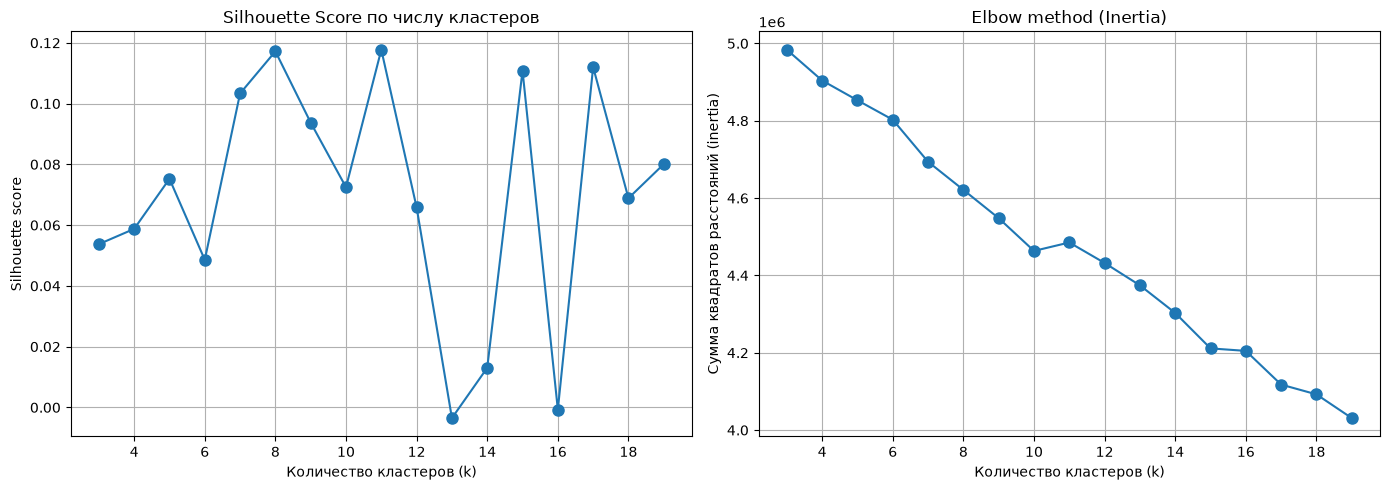


Наилучший k по silhouette score: 11 (score = 0.1177)


In [21]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

sil_scores = []
inertias = []
K = range(3, 20)

for k in K:
    print(f"Обработка k = {k} ...", end=" ")
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels, sample_size=min(2000, len(labels)), random_state=42)
    sil_scores.append(sil)
    inertias.append(kmeans.inertia_)
    print(f"silhouette = {sil:.4f}")

# Графики
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(K, sil_scores, 'o-', markersize=8)
plt.title('Silhouette Score по числу кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette score')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(K, inertias, 'o-', markersize=8)
plt.title('Elbow method (Inertia)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Сумма квадратов расстояний (inertia)')
plt.grid(True)

plt.tight_layout()
plt.show()

# Лучший k по силуэту
best_k = K[np.argmax(sil_scores)]
print(f"\nНаилучший k по silhouette score: {best_k} (score = {max(sil_scores):.4f})")

In [22]:
candidates = [7, 8, 11, 15, 17]

for k in candidates:
    print(f"\n{'='*80}\nK = {k}")
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)  # или X_scaled — какая у тебя сейчас
    df['cluster'] = labels

    for c in range(k):
        cl = df[df['cluster'] == c]
        size = len(cl)
        if size < 100: continue  # пропускаем очень мелкие, если хочешь

        print(f"\nКластер {c:2d}  —  {size:,} фильмов  ({size/len(df):.1%})")
        print("Примеры фильмов (случайные 8):")
        print(" • " + "\n • ".join(cl['title'].sample(8).tolist()))
        print("\nТоп-жанры:")
        print(cl['genres_list'].explode().value_counts().head(10))
        print("\nСредние / медианные характеристики:")
        print(cl[['year','runtime','vote_average','log_popularity','log_revenue']].agg(['mean','median']).round(2))
        print("-"*100)


K = 7



Кластер  0  —  393 фильмов  (0.9%)
Примеры фильмов (случайные 8):
 • So It Goes
 • Love Records
 • The magnetic man
 • Beyond
 • Raspberry Boat Refugee
 • The Disciple
 • Hellsinki
 • Ricky Rapper and Cool Wendy

Топ-жанры:
genres_list
Drama          198
Comedy         132
Documentary     49
Romance         40
Thriller        32
Crime           31
Family          25
Music           22
Action          22
Foreign         18
Name: count, dtype: int64

Средние / медианные характеристики:
           year  runtime  vote_average  log_popularity  log_revenue
mean    1999.86    90.54          5.31            0.51         0.74
median  2007.00    93.00          6.00            0.31         0.00
----------------------------------------------------------------------------------------------------

Кластер  1  —  29,601 фильмов  (66.6%)
Примеры фильмов (случайные 8):
 • The Exorcism of Molly Hartley
 • Highway to Hellas
 • Viva Villa!
 • Beyond Beauty: Taiwan from Above
 • Don't Call Me Son
 • The J


Кластер  0  —  7,881 фильмов  (17.7%)
Примеры фильмов (случайные 8):
 • Woman in Gold
 • (500) Days of Summer
 • Lone Wolf McQuade
 • Black Book
 • Hell Baby
 • The Next Three Days
 • Getaway
 • Friday the 13th Part VIII: Jason Takes Manhattan

Топ-жанры:
genres_list
Drama              3732
Comedy             2791
Thriller           2431
Action             2094
Adventure          1428
Romance            1417
Crime              1318
Horror              989
Science Fiction     962
Family              894
Name: count, dtype: int64

Средние / медианные характеристики:
           year  runtime  vote_average  log_popularity  log_revenue
mean    1998.94   106.95          6.18            2.16        12.40
median  2003.00   102.00          6.20            2.19        16.18
----------------------------------------------------------------------------------------------------

Кластер  1  —  31,710 фильмов  (71.4%)
Примеры фильмов (случайные 8):
 • Where Hope Grows
 • The Family Tree
 • Daffy Duck


Кластер  0  —  166 фильмов  (0.4%)
Примеры фильмов (случайные 8):
 • My Way Home
 • Woyzeck
 • Delta
 • Dough
 • Eragon
 • Essential Killing
 • Boy 7
 • Just Sex and Nothing Else

Топ-жанры:
genres_list
Drama        109
Comedy        33
Thriller      20
War           17
Romance       16
Animation     15
History       14
Crime         13
Family        12
Mystery       12
Name: count, dtype: int64

Средние / медианные характеристики:
           year  runtime  vote_average  log_popularity  log_revenue
mean    1997.83   101.04          5.87            0.80         1.57
median  2004.00   100.00          6.05            0.51         0.00
----------------------------------------------------------------------------------------------------

Кластер  1  —  7,819 фильмов  (17.6%)
Примеры фильмов (случайные 8):
 • My Best Friend's Girl
 • A Soldier's Story
 • Pokémon: Spell of the Unknown
 • The Outsiders
 • Coriolanus
 • The Pyramid
 • 4:44 Last Day on Earth
 • Boxing Helena

Топ-жанры:
genres_l


Кластер  0  —  6,586 фильмов  (14.8%)
Примеры фильмов (случайные 8):
 • Stealing Harvard
 • Equals
 • The King of Kong
 • Quest for Fire
 • Stonehearst Asylum
 • Goya's Ghosts
 • Juice
 • American Ninja

Топ-жанры:
genres_list
Drama              3131
Comedy             2363
Thriller           2024
Action             1715
Romance            1232
Adventure          1183
Crime              1127
Horror              824
Family              761
Science Fiction     756
Name: count, dtype: int64

Средние / медианные характеристики:
           year  runtime  vote_average  log_popularity  log_revenue
mean    1999.03   106.82          6.18            2.19        13.17
median  2003.00   103.00          6.20            2.22        16.45
----------------------------------------------------------------------------------------------------

Кластер  1  —  193 фильмов  (0.4%)
Примеры фильмов (случайные 8):
 • Measuring the World
 • Our Trip to Africa
 • Bad Fucking
 • Macondo
 • Dry Season
 • The Unint

 • Gamera vs. Guiron
 • Eden of the East Movie II: Paradise Lost
 • Shark Skin Man and Peach Hip Girl
 • Gothic & Lolita Psycho
 • Zatôichi's Revenge
 • The 47 Ronin
 • Grotesque
 • Scabbard Samurai

Топ-жанры:
genres_list
Drama              730
Action             478
Animation          414
Science Fiction    272
Comedy             238
Fantasy            209
Horror             193
Adventure          189
Thriller           181
Foreign            157
Name: count, dtype: int64

Средние / медианные характеристики:
           year  runtime  vote_average  log_popularity  log_revenue
mean    1991.71    99.42          6.22            0.91         1.13
median  2000.00   100.00          6.60            0.79         0.00
----------------------------------------------------------------------------------------------------

Кластер  9  —  337 фильмов  (0.8%)
Примеры фильмов (случайные 8):
 • Allez, Eddy!
 • Iron Eagle
 • Beperkt houdbaar
 • Heart Street
 • Seventh Heaven
 • The Bourne Identity
 • Fi


Кластер  0  —  626 фильмов  (1.4%)
Примеры фильмов (случайные 8):
 • Mammoth
 • The Paradise Suite
 • LasseMajas detektivbyrå - Stella Nostra
 • Intermezzo
 • All Things Fair
 • Swedenhielms
 • Young Sophie Bell
 • Jönssonligan spelar högt

Топ-жанры:
genres_list
Drama          354
Comedy         160
Thriller       112
Romance         65
Crime           61
Documentary     54
Family          52
Action          50
Mystery         41
Horror          35
Name: count, dtype: int64

Средние / медианные характеристики:
           year  runtime  vote_average  log_popularity  log_revenue
mean    1996.45    98.47          5.86            0.86         1.15
median  2004.00    97.00          6.10            0.70         0.00
----------------------------------------------------------------------------------------------------

Кластер  1  —  531 фильмов  (1.2%)
Примеры фильмов (случайные 8):
 • Nicht alle waren Mörder
 • The Brave Little Toaster
 • Cockneys vs Zombies
 • Past Life
 • Essential Killin

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances

# Fit the final model explicitly instead of depending on the previous loop.
labels = KMeans(n_clusters=17, random_state=42, n_init=10).fit_predict(X_scaled)
rng = np.random.default_rng(42)
intra_dist, inter_dist = [], []
for cluster in range(17):
    own = np.flatnonzero(labels == cluster)
    other = np.flatnonzero(labels != cluster)
    if len(own) < 2 or not len(other):
        continue
    own = rng.choice(own, size=min(500, len(own)), replace=False)
    other = rng.choice(other, size=min(500, len(other)), replace=False)
    distances = euclidean_distances(X_scaled[own])
    intra_dist.append(distances[np.triu_indices(len(own), k=1)].mean())
    inter_dist.append(euclidean_distances(X_scaled[own], X_scaled[other]).mean())
print(f"Mean within-cluster distance (sampled): {np.mean(intra_dist):.3f}")
print(f"Mean between-cluster distance (sampled): {np.mean(inter_dist):.3f}")
print(f"Between / within: {np.mean(inter_dist) / np.mean(intra_dist):.3f}")

Mean within-cluster distance (sampled): 12.945
Mean between-cluster distance (sampled): 18.896
Between / within: 1.460
